# Contact memory inferred from a real wet-quartz velocity step

## Problem, acquisition and scope
Infer direct-effect a, evolution coefficient b, characteristic slip Dc and positive internal state theta from914 measured friction/loadpoint observations of a wet ultrafine quartz layer. Confinement60MPa minus pore pressure20MPa gives40MPa effective stress. Machine stiffness and mass per contact area are independently known. The data are author processed and drift corrected; no actual true parameters or internal states exist.

The selected method is the paper's log-parameter trust-region nonlinear least-squares comparison, using its author spring-slider equations. This task does not claim a full Bayesian posterior, an aging-law fit or the historical manually selected window. Missing original JumpIdxs are replaced by the full stated observation window and loadpoint-only step timing. Rodas4 is named in the manuscript, Rosenbrock23 is used in the released original code, and the cleaned implementation explicitly extracts and validates the released Rosenbrock23 stages and adaptive controller. These differences are explicit.

In [1]:
from pathlib import Path
import sys,time,json
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if root.name=='notebooks':root=root.parent
sys.path.insert(0,str(root))
from src.preprocessing import prepare
from src.solvers import reconstruct,initial_guess,chi_square
from src.physics_model import trajectory,REFERENCE_VELOCITY
data=prepare(root/'data/raw_data.npz')
with np.load(root/'notebooks/reference_outputs/upstream_measurements.npz') as f:upstream={k:f[k] for k in f.files}
print('Full selected observations:',len(data['time']))
print('Observed steady-state b-a:',data['b_minus_a'],'inferred reference mu0:',data['mu0'])
print('Actual median sampling interval [s]:',np.median(np.diff(data['time'])))
print('No author fit or hidden state enters raw data.')

Full selected observations: 914
Observed steady-state b-a: -9.891333240898381e-05 inferred reference mu0: 0.693429168604745
Actual median sampling interval [s]: 0.1000000000003638
No author fit or hidden state enters raw data.


## Physics and method
The slider obeys $\dot x=V$ and $M\dot V=K(X+X_0-x)-\sigma\mu_{reg}-CV$. Here x is slider displacement, V slip rate, X prescribed loadpoint motion, X0 initial spring offset, M mass per area, K stress/displacement stiffness, sigma effective normal stress and C a small fixed dashpot coefficient. The state variable psi=log(Vref theta/Dc) obeys the slip law $\dot\psi=-(V/Dc)[\log(V/Vref)+\psi]$. Friction is mu0+a log(V/Vref)+b psi for the selected positive trajectory; an asinh regularization is used in the force balance. Theta measures contact memory in seconds.

The original method determines b-a and mu0 from the observed steady portions, fits log10(a),log10(Dc), and interpolates model outputs in measured loadpoint displacement. The author script incorrectly returns scalar chi-square to scipy least_squares, whose objective then becomes half the square of chi-square and whose Gauss-Newton matrix has rank at most one. We explicitly correct that interface to return all914 standardized residuals, matching the paper nonlinear least-squares objective. Physical equations, analytical initialization, bounds, default two-point parameter Jacobian and TRF stopping rules are preserved. The original Julia model is independently rerun twice with this interface correction; frozen tolerances remain unchanged. The local Rosenbrock23 implementation preserves the original five-component error norm, source tolerances, Hairer initial step and PI-controller deadband. All earlier scalar-interface and Radau numerical failures remain archived and superseded.

In [2]:
tick=time.perf_counter();fresh,info=reconstruct(data);runtime=time.perf_counter()-tick
np.savez_compressed(root/'output/reconstruction.npz',**fresh)
np.savez_compressed(root/'notebooks/reference_outputs/fresh_notebook_result.npz',**fresh)
print('Fresh complete inference seconds:',runtime)
print('Fresh [a,b,Dc(m)]:',fresh['reconstruction'][0])
print('Original independently executed [a,b,Dc(m)]:',upstream['reconstruction'][0])
print('Optimizer:',info['message'],'nfev:',info['nfev'],'chi-square:',info['objective'])
import importlib.util
spec=importlib.util.spec_from_file_location('independent_judge',root/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
metrics,thresholds=judge.score(fresh,upstream,data['friction'],json.loads((root/'evaluation/metrics.json').read_text()))
for name,value in metrics.items():print(name,value,'<=',thresholds[name]['boundary'])
assert all(metrics[k]<=r['boundary'] for k,r in thresholds.items())

Fresh complete inference seconds: 62.87582660000771
Fresh [a,b,Dc(m)]: [1.13102585e-02 1.12113452e-02 3.01255405e-06]
Original independently executed [a,b,Dc(m)]: [1.13103177e-02 1.12114043e-02 3.01253519e-06]
Optimizer: `ftol` termination condition is satisfied. nfev: 10 chi-square: 4616.35875028417
a_absolute_error 5.9154456616070106e-08 <= 0.0002
b_absolute_error 5.91544567114799e-08 <= 0.0002
Dc_absolute_error_m 1.8854648993674427e-11 <= 5e-08
state_maximum_absolute_error_s 6.284882990748031e-05 <= 0.05
velocity_relative_l2_error 2.632131246866252e-06 <= 0.005
friction_maximum_absolute_error 6.905400062873213e-08 <= 1e-05
observed_friction_RMS 0.0008989523443077488 <= 0.0009888476383917916


## Real observations, latent motion and fitted quantities
The comparison includes every bound observation, the complete original-method curve and the fresh full inversion. Model state and slider speed are sampled in measured displacement order and are labeled as inferences. Residual oscillation structure is visible, rather than being interpreted as zero uncertainty or removed from evaluation.

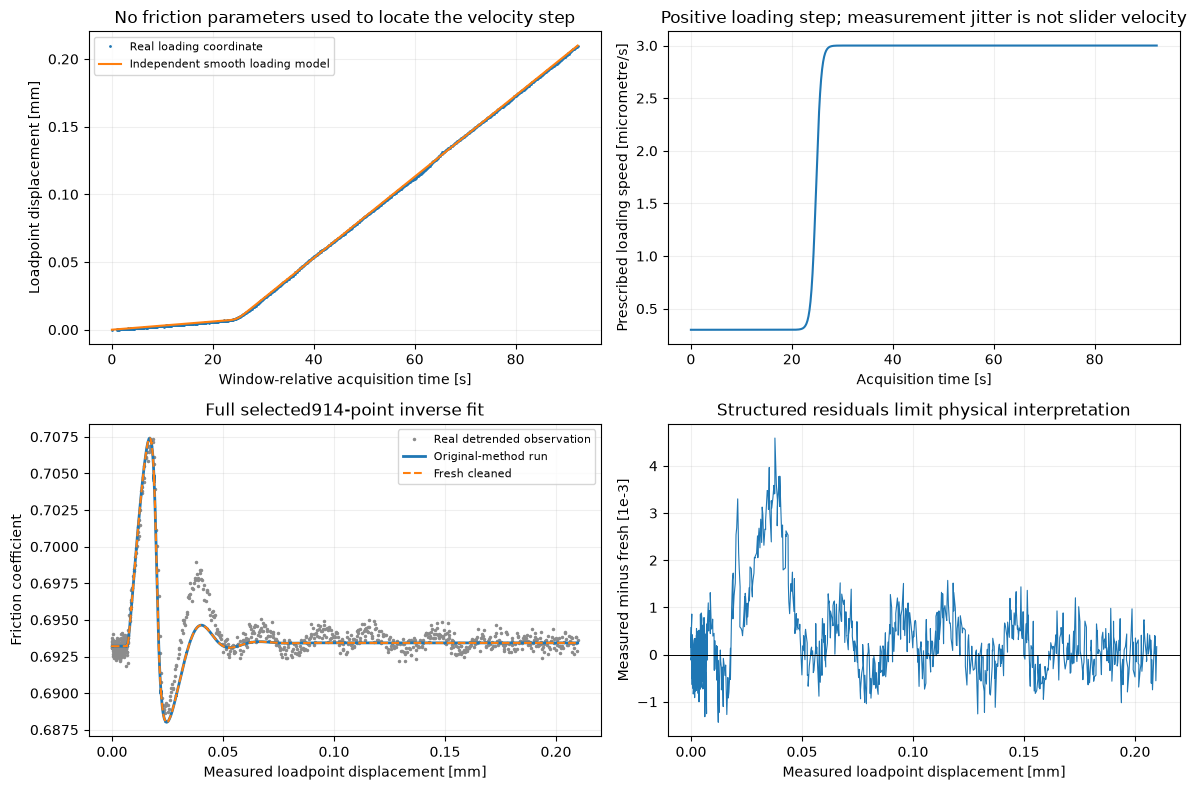

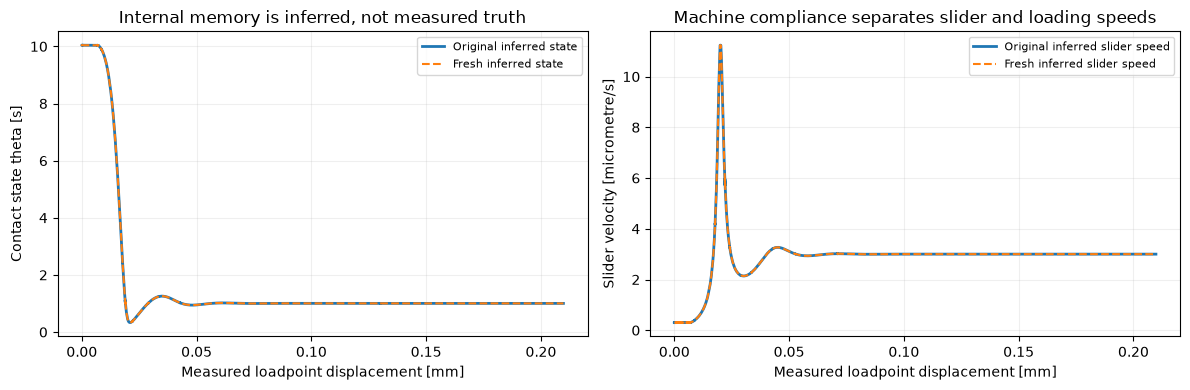

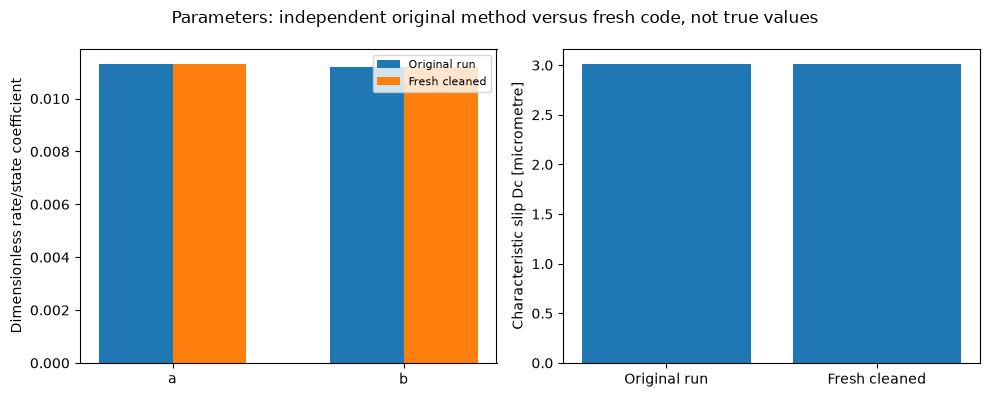

In [3]:
from src.visualization import review_figures
figures=review_figures(data,fresh,upstream)
for figure in figures:display(figure)
plt.close('all')

## Conditional local two-parameter uncertainty
The corrected residual-vector Jacobian supports a rank-two local NLS covariance. Compare the independently reproduced original covariance with the fresh covariance in log10(a),log10(Dc), scaled by residual chi-square/(914-2). These ellipses describe local model conditioning and the assumed residual model; structured measured residuals and fixed steady-state constraints prevent interpreting them as actual truth or Bayesian credible regions.

Fresh Jacobian singular values: [964.86623492 234.688054  ]
Fresh log-parameter covariance: [[ 3.33725412e-05 -4.04355144e-05]
 [-4.04355144e-05  6.39661294e-05]]
Original log-parameter covariance: [[ 3.33774294e-05 -4.04417198e-05]
 [-4.04417198e-05  6.39738432e-05]]


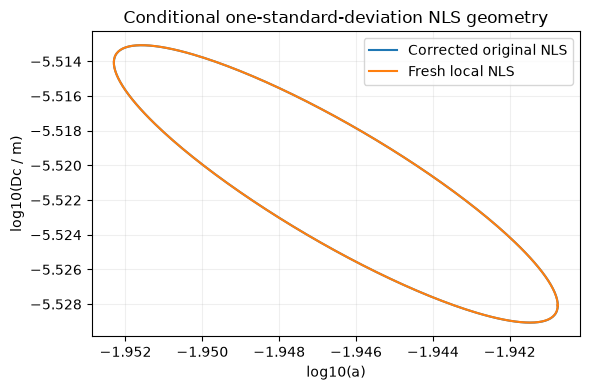

In [4]:
with np.load(root/'notebooks/reference_outputs/original_jacobian.npz') as f:
    original_jacobian=f['optimizer_jacobian']
fresh_covariance=np.linalg.inv(info['jacobian'].T@info['jacobian'])*info['objective']/(914-2)
original_covariance=np.linalg.inv(original_jacobian.T@original_jacobian)*np.sum(((data['friction']-upstream['friction'][0])/.0004)**2)/(914-2)
print('Fresh Jacobian singular values:',np.linalg.svd(info['jacobian'],compute_uv=False))
print('Fresh log-parameter covariance:',fresh_covariance)
print('Original log-parameter covariance:',original_covariance)
angles=np.linspace(0,2*np.pi,300);circle=np.array([np.cos(angles),np.sin(angles)])
fig,ax=plt.subplots(figsize=(6,4))
for cov,parameters,label in [(original_covariance,upstream['reconstruction'][0],'Corrected original NLS'),(fresh_covariance,fresh['reconstruction'][0],'Fresh local NLS')]:
    ellipse=np.linalg.cholesky(cov)@circle+np.log10(parameters[[0,2]])[:,None]
    ax.plot(ellipse[0],ellipse[1],label=label)
ax.set(xlabel='log10(a)',ylabel='log10(Dc / m)',title='Conditional one-standard-deviation NLS geometry');ax.legend();ax.grid(alpha=.2)
fig.tight_layout();display(fig);plt.close(fig)

## Fresh objective geometry and actual optimizer path
The published method emphasizes the characteristic slip scale. This fresh grid evaluates the selected scalar chi-square across independent physical parameter ranges and shows the actual cleaned optimizer evaluations. The logarithmic Dc axis resolves small slip distances. This is an objective landscape, not a posterior probability or credible interval.

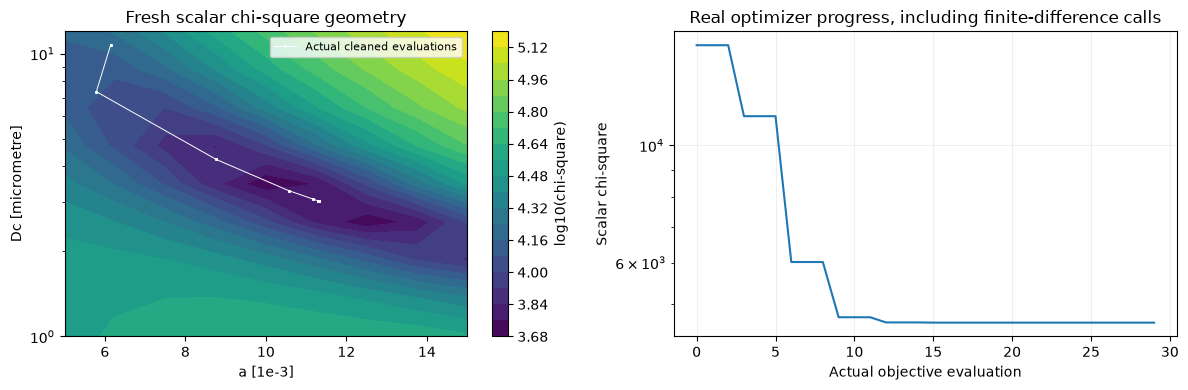

In [5]:
agrid=np.linspace(.005,.015,9);dgrid=np.geomspace(1e-6,12e-6,9)
surface=np.empty((len(dgrid),len(agrid)))
for row,Dc in enumerate(dgrid):
    for col,a in enumerate(agrid):surface[row,col]=chi_square(np.log10([a,Dc]),data)
history=np.array([r['log_parameters'] for r in info['history']]);physical=10**history
fig,axes=plt.subplots(1,2,figsize=(12,4))
image=axes[0].contourf(agrid*1000,dgrid*1e6,np.log10(surface),levels=20,cmap='viridis')
axes[0].plot(physical[:,0]*1000,physical[:,1]*1e6,'w.-',lw=.7,ms=2,label='Actual cleaned evaluations')
axes[0].set(yscale='log',xlabel='a [1e-3]',ylabel='Dc [micrometre]',title='Fresh scalar chi-square geometry');fig.colorbar(image,ax=axes[0],label='log10(chi-square)');axes[0].legend(fontsize=8)
axes[1].semilogy([r['chi_square'] for r in info['history']]);axes[1].set(xlabel='Actual objective evaluation',ylabel='Scalar chi-square',title='Real optimizer progress, including finite-difference calls');axes[1].grid(alpha=.2)
fig.tight_layout();display(fig);plt.close(fig)

## Apparatus sensitivity and state-law interpretation
Fresh forward calculations below use the fitted coefficients with the actual mass and with a lower mass200kg/m². They assess inertia sensitivity in this stable experiment and are explicitly not refits. A second panel evaluates the slip and aging state-law vector fields at the same speed and Dc, retaining the relevant model-family distinction without claiming a fresh aging-law inverse result. Full Bayesian chains, dry-condition inversions and aging-law refits are outside this bound selected NLS task.

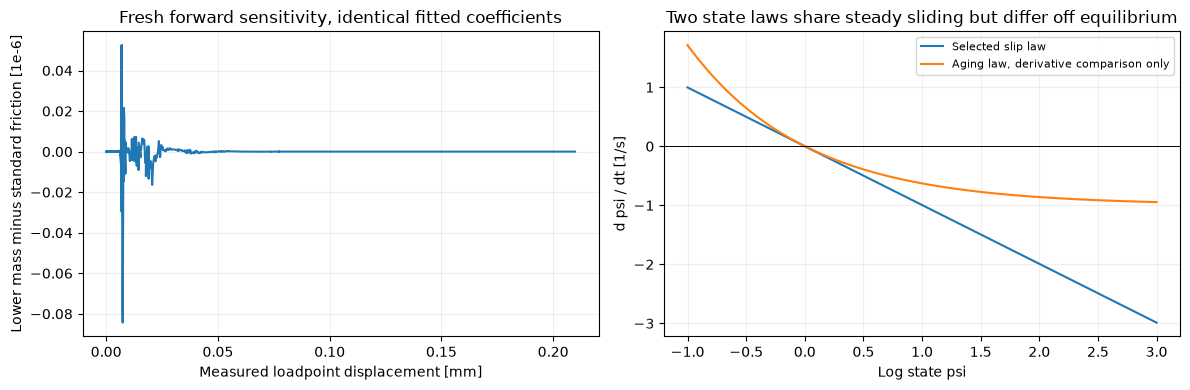

Fresh lower-mass maximum friction difference: 8.434326403961023e-08


641

In [6]:
a,b,Dc=fresh['reconstruction'][0]
lower_mass=trajectory(np.log10([a,Dc]),data,mass=200.)
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(data['displacement'],1e6*(lower_mass['friction'][0]-fresh['friction'][0]))
axes[0].set(xlabel='Measured loadpoint displacement [mm]',ylabel='Lower mass minus standard friction [1e-6]',title='Fresh forward sensitivity, identical fitted coefficients')
psi=np.linspace(-1,3,200);V=REFERENCE_VELOCITY
slip=-V/Dc*(np.log(V/REFERENCE_VELOCITY)+psi)
aging=REFERENCE_VELOCITY/Dc*np.exp(-psi)-V/Dc
axes[1].plot(psi,slip,label='Selected slip law');axes[1].plot(psi,aging,label='Aging law, derivative comparison only');axes[1].axhline(0,color='k',lw=.7)
axes[1].set(xlabel='Log state psi',ylabel='d psi / dt [1/s]',title='Two state laws share steady sliding but differ off equilibrium');axes[1].legend(fontsize=8)
for ax in axes:ax.grid(alpha=.2)
fig.tight_layout();display(fig);plt.close(fig)
print('Fresh lower-mass maximum friction difference:',np.max(abs(lower_mass['friction']-fresh['friction'])))
(root/'notebooks/reference_outputs/cleaned_measurements.json').write_text(json.dumps({'runtime_s':runtime,'metrics':metrics,'nfev':info['nfev'],'objective':info['objective'],'parameters':fresh['reconstruction'][0].tolist(),'lower_mass_friction_max_difference':float(np.max(abs(lower_mass['friction']-fresh['friction'])))},indent=2),encoding='utf8')

## Conclusion
The full fresh inverse path meets independently frozen original parameter, state, velocity, friction and real-data residual gates. Machine dynamics and displacement-domain comparison are explicit, with state and speed physically distinguished from loading motion. The low residual does not identify actual true parameters: drift processing, constrained steady-state values, structured oscillation residuals and the selected contact model limit interpretation. Earlier scalar-interface and numerical-backend failures remain archived and are not counted as passed fits.

Kim etal., GJI247(2026),ggag362, DOI10.1093/gji/ggag362; exact author data/scripts DOI10.5281/zenodo.21401458, CC-BY4.0.